# MicroCT step 0a — convert the NFP scan

Raw DanMAX orca frames to `data_nfp.h5`, the file `step0.py` reads.

Scan 93 has the weak CA (stays in from scan 92 on) and the strong CA (moving,
121 positions) in the beam, and **no sample** — near-field ptychography on it
recovers the strong CA. Dark comes from scan 90 and the flat from scan 91.

**Two apertures, as in every folder here**: the weak CA is static and ends up
folded into the probe; the strong CA is the one that moves and is the `code`
variable. So `prb.npy` (written by `step0.py`) is *the beam with the weak CA
already imprinted on it* — not a clean illumination function.

This notebook writes everything except the scan positions, which need
cross-correlation and are done in
[`step0b_shifts.ipynb`](step0b_shifts.ipynb).

Output, matching what `step0.py` expects:

```
/exchange/pdata   [npos, nz, n]  float32   dark- and flat-corrected INTENSITY
/exchange/pref    [nz, n]        float32   beam x weak CA (scan 92's mean)
/exchange/{energy, z1, detector_pixelsize, focusdetectordistance, voxelsize}
```

**This orca crop is centred SQUARE**, 2048 x 2048 out of 2592 x 4608 — unlike
the standalone `BoneNano_nfp`'s rectangular 2048 x 4096. Square here because
the code plane must be square regardless (`npsiz == npsi`), and there is no
tomography reason to prefer a rectangle the way `BoneNano_nfp` did.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../../src'))
import numpy as np, cupy as cp, h5py
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

def cbshow(ax, img, title, cmap='gray', **kw):
    im = ax.imshow(np.asarray(img), cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    cax = make_axes_locatable(ax).append_axes('right', size='5%', pad=0.05)
    ax.figure.colorbar(im, cax=cax)

print('GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())

GPU: NVIDIA A100-SXM4-40GB


## Config

In [2]:
# --- everything comes from config_step0.conf. Edit THAT file, not this cell.
from holotomocupy.config import parse_args_coded_step0
CFG = parse_args_coded_step0('config_step0.conf')

RAW_DIR = CFG.raw_nfp          # raw DanMAX scans, read-only
OUT_DIR = CFG.path             # where data_nfp.h5 goes

DARK_H5   = f'{RAW_DIR}/scan-0090_orca.h5'   # dark
FLAT_H5   = f'{RAW_DIR}/scan-0091_orca.h5'   # flat: NO CA at all
WEAKCA_H5 = f'{RAW_DIR}/scan-0092_orca.h5'   # weak CA alone, no sample -> pref
GRID_H5   = f'{RAW_DIR}/scan-0093_orca.h5'   # weak + strong CA, no sample, 121 positions
ORCA      = '/entry/instrument/orca/data'

# Geometry, also from the config. step0.py reads these back out of the HDF5
# this notebook writes, so there is exactly one place they are defined.
ENERGY   = CFG.energy_kev
Z1       = CFG.z1_m                            # focus -> CA2 (the NFP "sample" plane)
Z_DET    = CFG.focusdetectordistance_m
DET_PIX  = CFG.detector_pixelsize_m            # UNBINNED
BIN      = CFG.bin
nz, n    = CFG.nz, CFG.n                       # BINNED grid
CROP     = (nz << BIN, n << BIN)               # centred crop, implied by the two
DEZINGER = ((CFG.dezinger_radius, CFG.dezinger_threshold)
            if CFG.dezinger_radius else None)

for _k, _v in (('energy', ENERGY), ('z1', Z1),
               ('focusdetectordistance', Z_DET),
               ('detector_pixelsize', DET_PIX)):
    if _v is None:
        raise SystemExit(f'config_step0.conf is missing {_k}')
print(f'from config: {ENERGY} keV, z1 {Z1} m, z_det {Z_DET} m, '
      f'det_px {DET_PIX*1e9:.1f} nm, bin {BIN}, crop {CROP} -> {nz} x {n}')

os.makedirs(OUT_DIR, exist_ok=True)

from config: 19.9 keV, z1 0.14125 m, z_det 0.74625 m, det_px 230.0 nm, bin 0, crop (2048, 2048) -> 2048 x 2048


## Geometry

In [3]:
det_pix_bin = DET_PIX * 2 ** BIN
mag         = Z_DET / Z1
voxelsize   = det_pix_bin / mag
wavelength  = 1.24e-9 / ENERGY
distance    = Z1 * (Z_DET - Z1) / Z_DET          # parallel-beam-equivalent

with h5py.File(GRID_H5, 'r') as f:
    NPOS, NY, NX = f[ORCA].shape
cy, cx = NY // 2, NX // 2
SL = (slice(cy - CROP[0] // 2, cy + CROP[0] // 2),
      slice(cx - CROP[1] // 2, cx + CROP[1] // 2))

print(f'orca {NY} x {NX}, {NPOS} positions')
print(f'crop {CROP} -> bin {BIN} -> nz x n = {nz} x {n}')
print(f'voxel {voxelsize*1e9:.2f} nm   D {distance*1e3:.4f} mm   '
      f'lambda {wavelength:.4e} m   mag {mag:.3f}')

orca 2592 x 4608, 121 positions
crop (2048, 2048) -> bin 0 -> nz x n = 2048 x 2048
voxel 43.53 nm   D 114.5142 mm   lambda 6.2312e-11 m   mag 5.283


## Dark, flat, dead-pixel mask

In [4]:
# The four preprocessing helpers, inlined. Ports of
# phascade.preprocess.{dark_subtract_clip, fill_dead, remove_outliers,
# flat_field_divide} -- what the bone_nano notebooks used on THIS detector.
# holotomocupy has no equivalents, so they live here.
from cupyx.scipy.ndimage import median_filter

def dark_subtract_clip(data, dark_mean):
    out = np.asarray(data, 'float32') - dark_mean[np.newaxis]
    np.clip(out, 0, None, out=out)
    return out

def _runs(idx):
    return [] if len(idx) == 0 else np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)

def fill_dead(data, mask):
    # Linearly interpolate over dead detector ROWS/COLUMNS.
    out = np.array(data, copy=True)
    ny, nx = mask.shape
    for g in _runs(np.where(mask.mean(1) > 0.5)[0]):
        lo, hi = g[0] - 1, g[-1] + 1
        hl, hh = lo >= 0, hi < ny
        for r in g:
            if hl and hh:
                w = (r - lo) / (hi - lo)
                out[..., r, :] = (1 - w) * out[..., lo, :] + w * out[..., hi, :]
            elif hl:
                out[..., r, :] = out[..., lo, :]
            elif hh:
                out[..., r, :] = out[..., hi, :]
    for g in _runs(np.where(mask.mean(0) > 0.5)[0]):
        lo, hi = g[0] - 1, g[-1] + 1
        hl, hh = lo >= 0, hi < nx
        for c in g:
            if hl and hh:
                w = (c - lo) / (hi - lo)
                out[..., :, c] = (1 - w) * out[..., :, lo] + w * out[..., :, hi]
            elif hl:
                out[..., :, c] = out[..., :, lo]
            elif hh:
                out[..., :, c] = out[..., :, hi]
    return out

def remove_outliers(data, radius=3, threshold=0.8):
    # Dezinger against the local median. Window is radius x radius, NOT
    # 2*radius+1 -- matches phascade.preprocess.remove_outliers.
    res = np.asarray(data, 'float32').copy()
    for k in range(res.shape[0]):
        f = cp.asarray(res[k])
        med = median_filter(f, [radius, radius])
        res[k] = cp.asnumpy(cp.where(cp.abs(f - med) > med * threshold, med, f))
    return res

def flat_field_divide(frames, flat_mean):
    # Normalise by the SCALAR mean flat level, nan-safe (~1 in air).
    fmean = float(np.asarray(flat_mean).mean()) + 1e-12
    return np.nan_to_num(np.asarray(frames, 'float32') / fmean, nan=1.0)

def bin2(a, nbin):
    for _ in range(nbin):
        a = 0.5 * (a[..., 0::2, :] + a[..., 1::2, :])
        a = 0.5 * (a[..., :, 0::2] + a[..., :, 1::2])
    return a

dead threshold 710.2 ADU   dead pixels 0
  dead rows []
  dead cols []
dark mean   197.55 std   1.67
flat mean 14195.98  normalised range [0.5914, 1.5084]


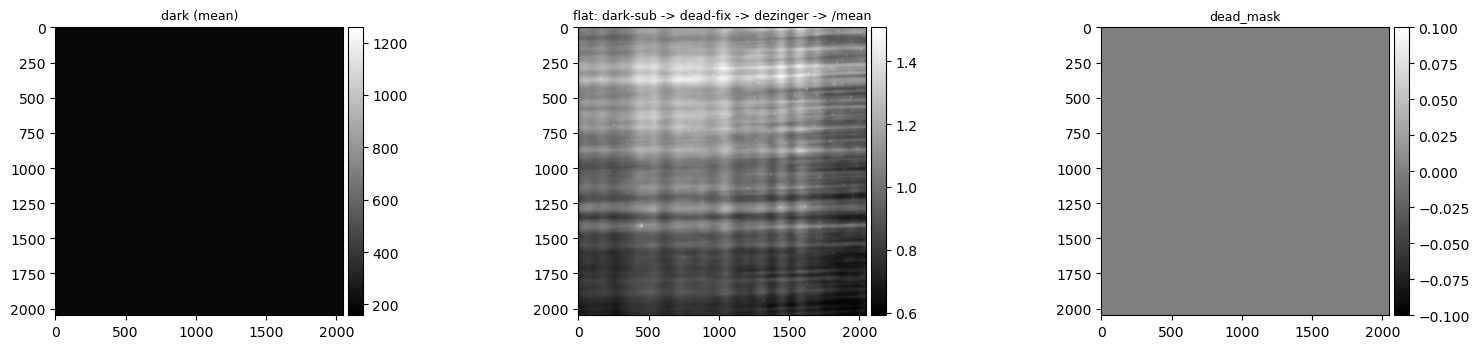

In [5]:
def _mean_stack(path, sl):
    with h5py.File(path, 'r') as f:
        d = f[ORCA]
        acc = np.zeros((sl[0].stop - sl[0].start, sl[1].stop - sl[1].start), 'float64')
        for i in range(d.shape[0]):
            acc += d[i, sl[0], sl[1]]
        return (acc / d.shape[0]).astype('float32')

dark = _mean_stack(DARK_H5, SL)
flat = dark_subtract_clip(_mean_stack(FLAT_H5, SL)[None], dark)[0]

# Dead pixels, from the flat: anything at 5% of the median open-beam level is
# not responding. Leaving them in means the solver fits detector failure as
# signal.
thr = 0.05 * np.median(flat[flat > 0])
dead_mask = flat < thr
print(f'dead threshold {thr:.1f} ADU   dead pixels {int(dead_mask.sum())}')
print('  dead rows', np.where(dead_mask.mean(1) > 0.5)[0].tolist())
print('  dead cols', np.where(dead_mask.mean(0) > 0.5)[0].tolist())

flat = fill_dead(flat[None], dead_mask)[0]
if DEZINGER:
    flat = remove_outliers(flat[None], *DEZINGER)[0]

flat_mean = float(flat.mean())                 # the SCALAR normalisation
flat_norm = (flat / flat_mean).astype('float32')
print(f'dark mean {dark.mean():8.2f} std {dark.std():6.2f}')
print(f'flat mean {flat_mean:8.2f}  normalised range '
      f'[{flat_norm.min():.4f}, {flat_norm.max():.4f}]')

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
cbshow(ax[0], dark, 'dark (mean)')
cbshow(ax[1], flat_norm, 'flat: dark-sub -> dead-fix -> dezinger -> /mean')
cbshow(ax[2], dead_mask.astype('float32'), 'dead_mask')
plt.tight_layout(); plt.show()

## Diagnostic: is the flat free of structure the mask should own?

Scan 91 has no CA at all, so what is left is the bare beam plus detector
response. Any sharp periodic texture here would mean a mask was still in, and
it would then be divided out of the data as if it were illumination.

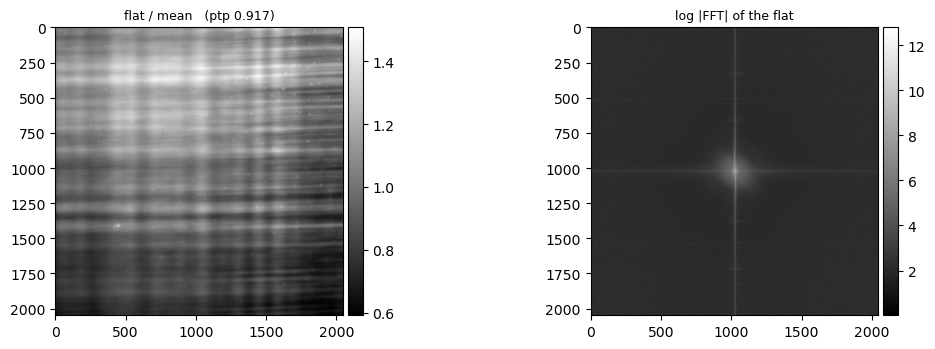

flat relative std: 0.17122624814510345


In [6]:
f0 = flat_norm                       # already dark-subtracted, dead-fixed, /mean
ps = np.abs(np.fft.fftshift(np.fft.fft2(f0 - f0.mean())))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cbshow(ax[0], f0, f'flat / mean   (ptp {np.ptp(f0):.3f})')
cbshow(ax[1], np.log1p(ps), 'log |FFT| of the flat')
plt.tight_layout(); plt.show()
print('flat relative std:', float(f0.std()))

## The probe reference: scan 92 (weak CA alone)

Scan 92 is a 100-frame average of beam x weak CA, taken with the weak CA
already in its final position -- the logbook's own words are "From now on,
the weak CA stays in". This is a direct, averaged measurement of what
`step0.py` calls `pref`, and is a better reference than `BoneNano_nfp` had:
there, no clean CA1-alone-at-the-right-time scan existed, so the probe had to
be seeded from the NFP scan's own mean frame instead.

Processed through the SAME chain as everything else -- stage 0 and stage 1
must preprocess identically, or the warm start does not match the data it is
meant to explain.

pref (beam x weak CA, scan 92 mean of 100 frames): (2048, 2048)  mean 0.9733  range [0.5402, 1.5663]


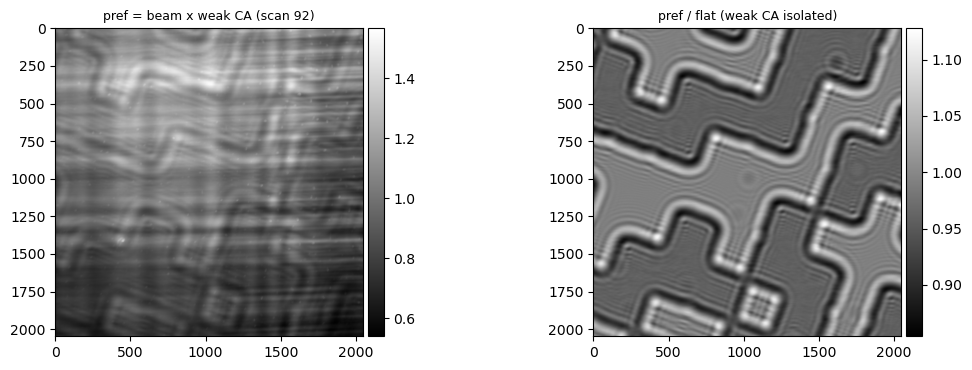

In [7]:
pref_raw = np.empty((100, nz, n), 'float32')
with h5py.File(WEAKCA_H5, 'r') as f:
    NWEAK = f[ORCA].shape[0]
    CHUNK = 8 if BIN == 0 else 32
    for cs in range(0, NWEAK, CHUNK):
        ce = min(cs + CHUNK, NWEAK)
        raw = np.asarray(f[ORCA][cs:ce, SL[0], SL[1]], 'float32')
        raw = dark_subtract_clip(raw, dark)
        raw = fill_dead(raw, dead_mask)
        if DEZINGER:
            raw = remove_outliers(raw, *DEZINGER)
        raw = flat_field_divide(raw, flat_mean)
        pref_raw[cs:ce] = bin2(raw, BIN)
pref = pref_raw.mean(0)
del pref_raw
print(f'pref (beam x weak CA, scan 92 mean of {NWEAK} frames): {pref.shape}  '
      f'mean {pref.mean():.4f}  range [{pref.min():.4f}, {pref.max():.4f}]')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cbshow(ax[0], pref, 'pref = beam x weak CA (scan 92)')
cbshow(ax[1], pref / (flat_norm + 1e-6), 'pref / flat (weak CA isolated)')
plt.tight_layout(); plt.show()

## Preprocess scan 93 (the NFP scan)

The same chain, in the same order:

```
dark_subtract_clip -> fill_dead -> remove_outliers -> flat_field_divide -> bin
```

The flat is divided out as a **scalar**, not per pixel -- the reference still
carries the weak CA, so a per-pixel divide would remove structure the forward
model is meant to reconstruct as part of the probe.

At `bin=0` this is crop-only and `bin2` is a no-op, which is the production
setting here. `pdata` is `npos x nz x n` float32 held in RAM before it is
written: 121 x 2048 x 2048 is about **2 GB**.

pdata (121, 2048, 2048) float32  range [0.3844, 2.0325]  mean 0.9320


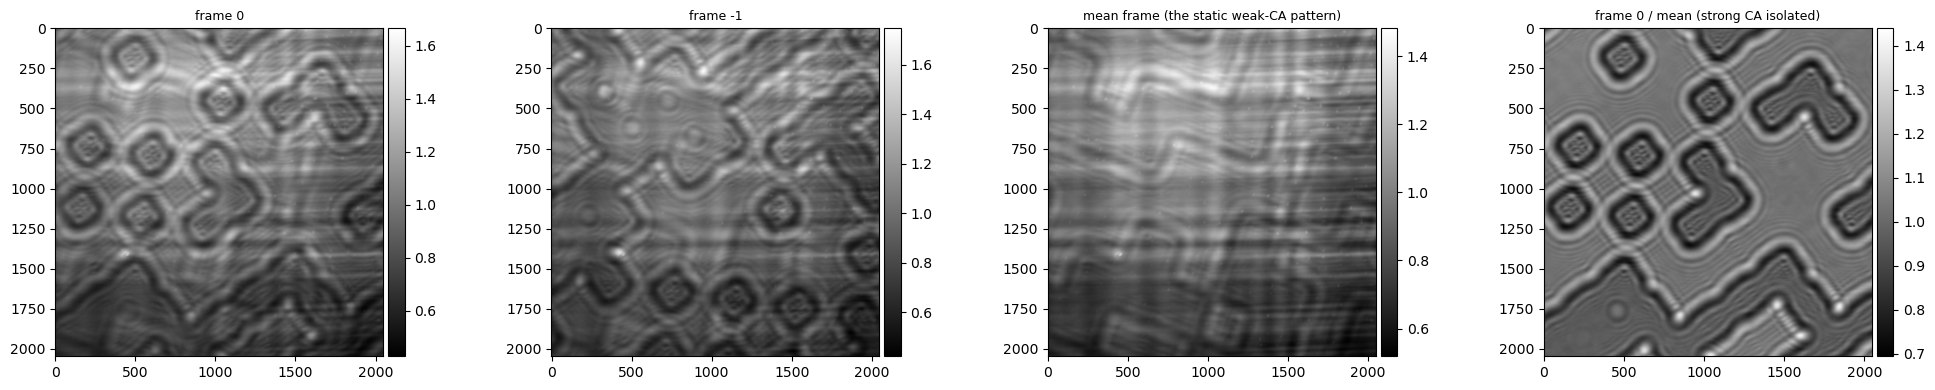

In [8]:
CHUNK = 8 if BIN == 0 else 32      # unbinned frames are 64x bigger

pdata = np.empty((NPOS, nz, n), 'float32')
with h5py.File(GRID_H5, 'r') as f:
    for cs in range(0, NPOS, CHUNK):
        ce = min(cs + CHUNK, NPOS)
        raw = np.asarray(f[ORCA][cs:ce, SL[0], SL[1]], 'float32')
        raw = dark_subtract_clip(raw, dark)
        raw = fill_dead(raw, dead_mask)
        if DEZINGER:
            raw = remove_outliers(raw, *DEZINGER)
        raw = flat_field_divide(raw, flat_mean)
        pdata[cs:ce] = bin2(raw, BIN)

print(f'pdata {pdata.shape} {pdata.dtype}  range [{pdata.min():.4f}, {pdata.max():.4f}]'
      f'  mean {pdata.mean():.4f}')

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
cbshow(ax[0], pdata[0], 'frame 0')
cbshow(ax[1], pdata[-1], 'frame -1')
cbshow(ax[2], pdata.mean(0), 'mean frame (the static weak-CA pattern)')
cbshow(ax[3], pdata[0] / (pdata.mean(0) + 1e-3), 'frame 0 / mean (strong CA isolated)')
plt.tight_layout(); plt.show()

## Diagnostic: does the mask speckle actually survive binning?

If `bin` is raised later, check this again -- a coarse enough bin erases the
speckle the reconstruction lives on before the solver ever sees it.

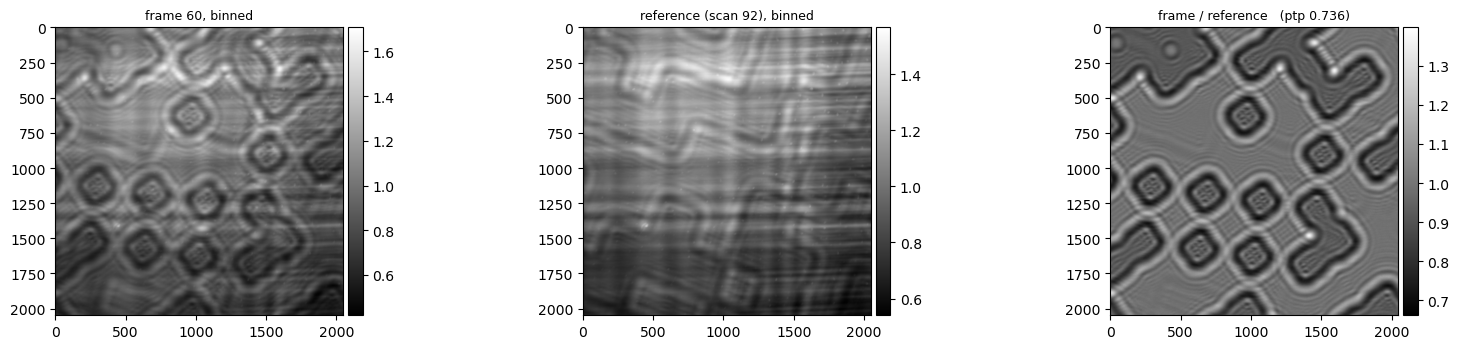

speckle relative std after binning: 0.08910336345434189


In [9]:
k = NPOS // 2
rd = pdata[k] / np.maximum(pref, 1e-6)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
cbshow(ax[0], pdata[k], f'frame {k}, binned')
cbshow(ax[1], pref, 'reference (scan 92), binned')
cbshow(ax[2], rd, f'frame / reference   (ptp {np.ptp(rd):.3f})')
plt.tight_layout(); plt.show()
print('speckle relative std after binning:', float(rd.std()))

## Write `data_nfp.h5`

In [10]:
out = f'{OUT_DIR}/data_nfp.h5'
with h5py.File(out, 'w') as f:
    f.create_dataset('/exchange/pdata', data=pdata)
    f.create_dataset('/exchange/pref',  data=pref)
    # ONE convention across the whole pipeline: geometry is stored UNBINNED
    # and each consumer scales by its own `bin`. step0.py scales
    # detector_pixelsize by 2**bin on the way in.
    for k_, v_ in (('energy', ENERGY), ('z1', Z1),
                   ('focusdetectordistance', Z_DET),
                   ('detector_pixelsize', DET_PIX),          # UNBINNED
                   ('voxelsize', voxelsize),                 # at THIS bin, informational
                   ('ref_norm', flat_mean)):
        f.create_dataset(f'/exchange/{k_}', data=np.array([v_], 'float64'))
print('wrote', out)
print(f'detector_pixelsize written UNBINNED ({DET_PIX*1e9:.1f} nm); '
      f'step0.py scales it by 2**bin = {2**BIN}')
print('Next: step0b_shifts.ipynb adds /exchange/shifts.')

wrote /data3/cekmekci/MicroCT_coded_holo/nfp/data_nfp.h5
detector_pixelsize written UNBINNED (230.0 nm); step0.py scales it by 2**bin = 1
Next: step0b_shifts.ipynb adds /exchange/shifts.
